In [4]:
import numpy as np
import pandas as pd

In [5]:
df = pd.read_csv("spam (1).csv", encoding='latin1')

In [6]:
print(df.head());

     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  


In [7]:
df.shape

(5572, 5)

In [8]:
# 1. Data Cleaning
# 2. EDA (Exploratory Data Analysis)
# 3. Text Preprocessing
# 4. Model Building
# 5. Evaluation
# 6. Improvement
# 7. Website
# 8. Deploy

## Data Cleaning

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [10]:
# Drop last three columns
df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], inplace=True)

In [11]:
print(df.sample(5)); #Gives random five rows

        v1                                                 v2
3204   ham  Oh, yes, I've just been a little under the wea...
851    ham  I am real, baby! I want to bring out your inne...
1367   ham  I don't know, same thing that's wrong everyso ...
1803   ham                 I'm in class. Did you get my text.
1593  spam  PRIVATE! Your 2003 Account Statement for shows...


In [12]:
# Reanming the columns
df.rename(columns={'v1': 'target', 'v2': 'text'}, inplace=True)
print(df.sample(5))

     target                                               text
1725    ham  You know there is. I shall speak to you in  &l...
4502    ham                            Stupid.its not possible
4736    ham  Nt only for driving even for many reasons she ...
2732    ham  How dare you stupid. I wont tell anything to y...
2518    ham  Joy's father is John. Then John is the NAME of...


In [13]:
# Encoding the target column
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [14]:
df['target'] = encoder.fit_transform(df['target'])
print(df.head())

   target                                               text
0       0  Go until jurong point, crazy.. Available only ...
1       0                      Ok lar... Joking wif u oni...
2       1  Free entry in 2 a wkly comp to win FA Cup fina...
3       0  U dun say so early hor... U c already then say...
4       0  Nah I don't think he goes to usf, he lives aro...


In [15]:
# missing values
df.isnull().sum()

target    0
text      0
dtype: int64

In [16]:
# check duplicate values
df.duplicated().sum()

np.int64(403)

In [17]:
# remove duplicates
df = df.drop_duplicates(keep='first')
df.duplicated().sum()

np.int64(0)

In [18]:
df.shape

(5169, 2)

## EDA

In [19]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

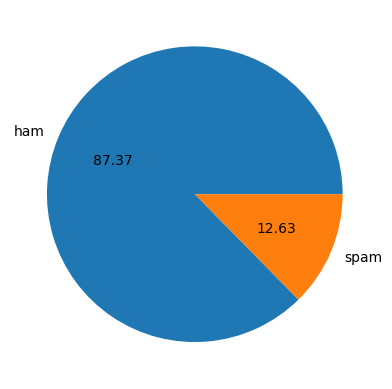

In [20]:
import matplotlib.pyplot as plt
plt.pie(df['target'].value_counts(), labels=['ham', 'spam'], autopct="%0.2f")
plt.show()

In [21]:
# Data is imbalanced

In [22]:
import nltk

In [23]:
!pip install nltk

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [24]:
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Abhra9\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Abhra9\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [25]:
df['num_characters'] = df['text'].apply(len)

In [26]:
print(df.head())

   target                                               text  num_characters
0       0  Go until jurong point, crazy.. Available only ...             111
1       0                      Ok lar... Joking wif u oni...              29
2       1  Free entry in 2 a wkly comp to win FA Cup fina...             155
3       0  U dun say so early hor... U c already then say...              49
4       0  Nah I don't think he goes to usf, he lives aro...              61


In [27]:
df['num_words'] = df['text'].apply(lambda x: len(nltk.word_tokenize(x)))

In [28]:
print(df.head())

   target                                               text  num_characters  \
0       0  Go until jurong point, crazy.. Available only ...             111   
1       0                      Ok lar... Joking wif u oni...              29   
2       1  Free entry in 2 a wkly comp to win FA Cup fina...             155   
3       0  U dun say so early hor... U c already then say...              49   
4       0  Nah I don't think he goes to usf, he lives aro...              61   

   num_words  
0         24  
1          8  
2         37  
3         13  
4         15  


In [29]:
df['num_sents'] = df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))

In [30]:
print(df.head())

   target                                               text  num_characters  \
0       0  Go until jurong point, crazy.. Available only ...             111   
1       0                      Ok lar... Joking wif u oni...              29   
2       1  Free entry in 2 a wkly comp to win FA Cup fina...             155   
3       0  U dun say so early hor... U c already then say...              49   
4       0  Nah I don't think he goes to usf, he lives aro...              61   

   num_words  num_sents  
0         24          2  
1          8          2  
2         37          2  
3         13          1  
4         15          1  


In [31]:
df[['num_characters', 'num_words', 'num_sents']].describe()

,num_characters,num_words,num_sents
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [32]:
df[df.target==0][['num_characters', 'num_words', 'num_sents']].describe()

,num_characters,num_words,num_sents
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [33]:
df[df.target==1][['num_characters', 'num_words', 'num_sents']].describe()

,num_characters,num_words,num_sents
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [34]:
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

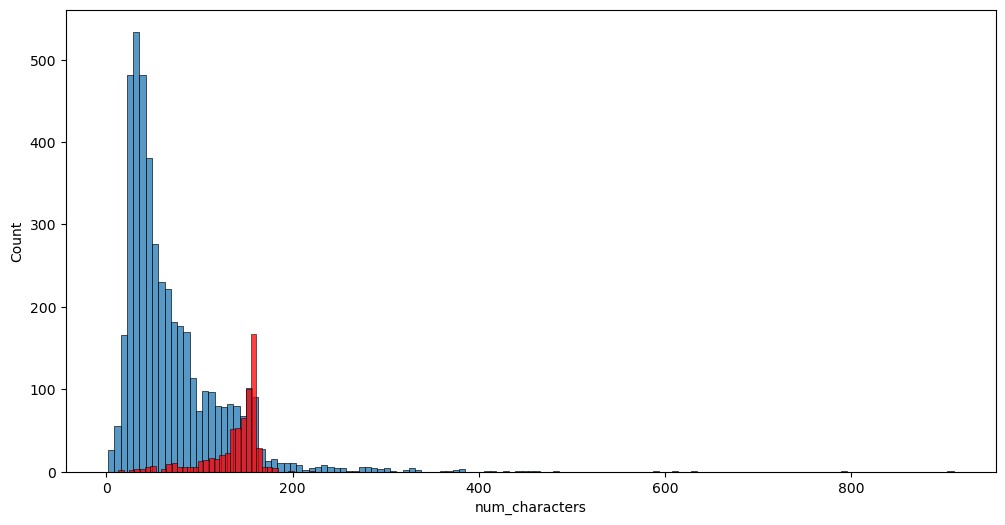

In [35]:
plt.figure(figsize=(12, 6))
sns.histplot(df[df.target==0]['num_characters'])
sns.histplot(df[df.target==1]['num_characters'], color='red')

<Axes: xlabel='num_words', ylabel='Count'>

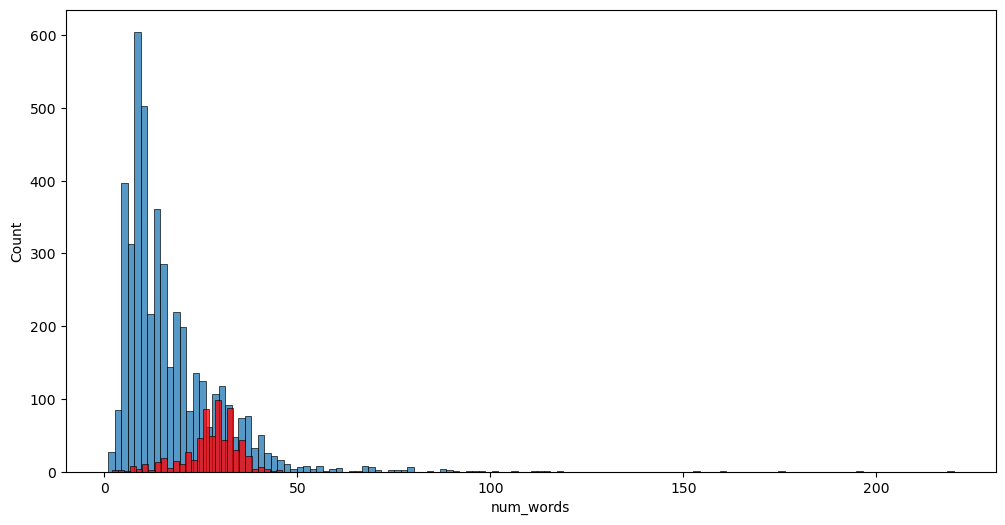

In [36]:
plt.figure(figsize=(12, 6))
sns.histplot(df[df.target==0]['num_words'])
sns.histplot(df[df.target==1]['num_words'], color='red')

<Axes: xlabel='num_sents', ylabel='Count'>

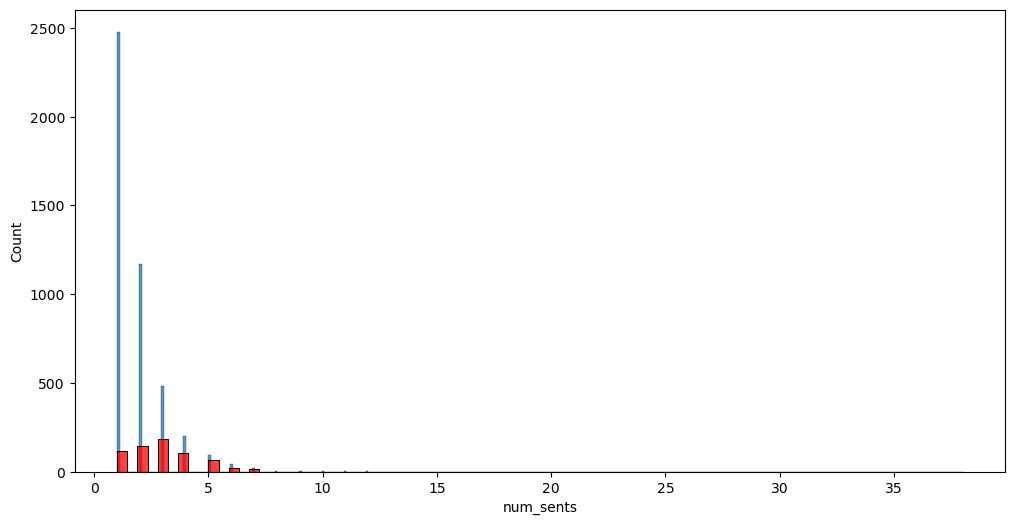

In [37]:
plt.figure(figsize=(12, 6))
sns.histplot(df[df.target==0]['num_sents'])
sns.histplot(df[df.target==1]['num_sents'], color='red')

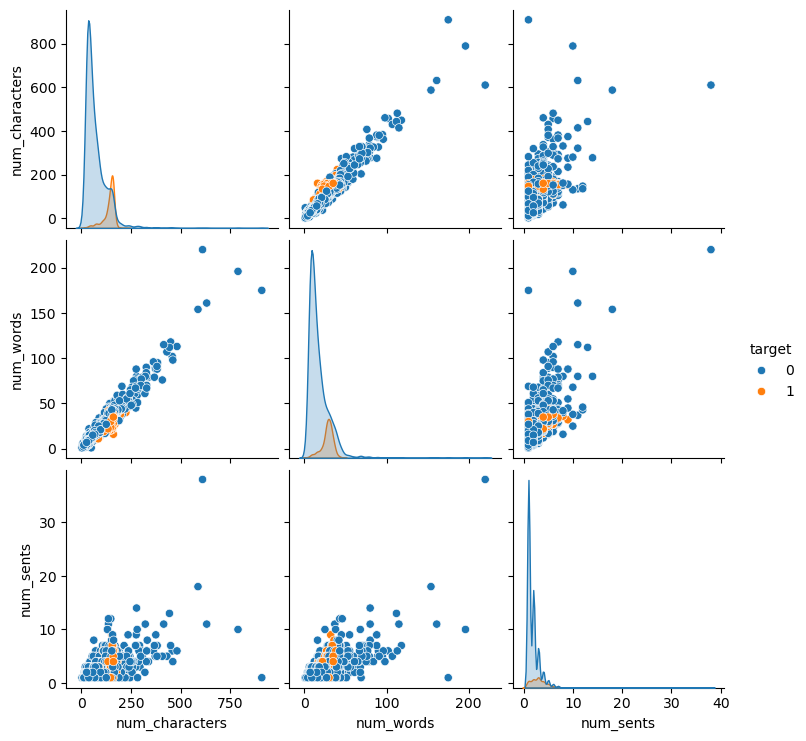

In [38]:
# Plotting relationship between the three
sns.pairplot(df, hue='target')

In [39]:
df.drop(columns=['text']).corr()

,target,num_characters,num_words,num_sents
target,1.000000,0.384717,0.262912,0.263939
num_characters,0.384717,1.000000,0.965760,0.624139
num_words,0.262912,0.965760,1.000000,0.679971
num_sents,0.263939,0.624139,0.679971,1.000000


<Axes: >

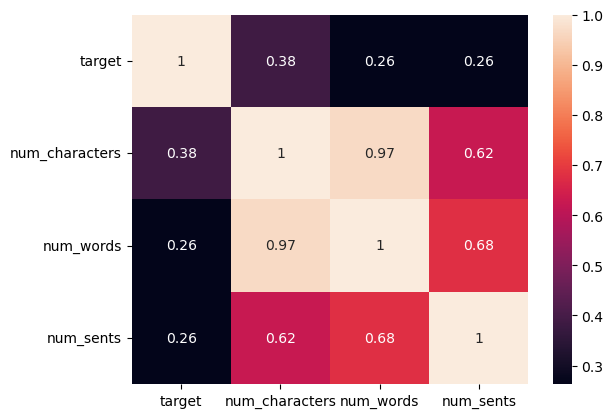

In [40]:
sns.heatmap(df.drop(columns=['text']).corr(), annot=True)

In [41]:
# We note that num_characters has highest correlation with target

## Data Preprocessing
- Lower case
- Tokenization
- Removing special characters
- Removing stop words and punctuations
- Stemming

In [42]:
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Abhra9\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [43]:
import string

In [44]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
ps.stem("loving")

'love'

In [45]:
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y = []
    for i in text:
        if i.isalnum:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)

In [46]:
transform_text("Did you like my presentation on ML?")

'like present ml'

In [47]:
transform_text("I loved the match. What about you?")

'love match'

In [48]:
df['transformed_text'] = df['text'].apply(transform_text)

In [49]:
print(df.head())
print(df.columns)

   target                                               text  num_characters  \
0       0  Go until jurong point, crazy.. Available only ...             111   
1       0                      Ok lar... Joking wif u oni...              29   
2       1  Free entry in 2 a wkly comp to win FA Cup fina...             155   
3       0  U dun say so early hor... U c already then say...              49   
4       0  Nah I don't think he goes to usf, he lives aro...              61   

   num_words  num_sents                                   transformed_text  
0         24          2  go jurong point crazi .. avail bugi n great wo...  
1          8          2                      ok lar ... joke wif u oni ...  
2         37          2  free entri 2 wkli comp win fa cup final tkt 21...  
3         13          1        u dun say earli hor ... u c alreadi say ...  
4         15          1           nah n't think goe usf live around though  
Index(['target', 'text', 'num_characters', 'num_words', '

In [50]:
!pip install wordcloud

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [51]:
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white', prefer_horizontal=1.0)

In [52]:
spam_wc = wc.generate(df[df['target']==1]['transformed_text'].str.cat(sep=" "))

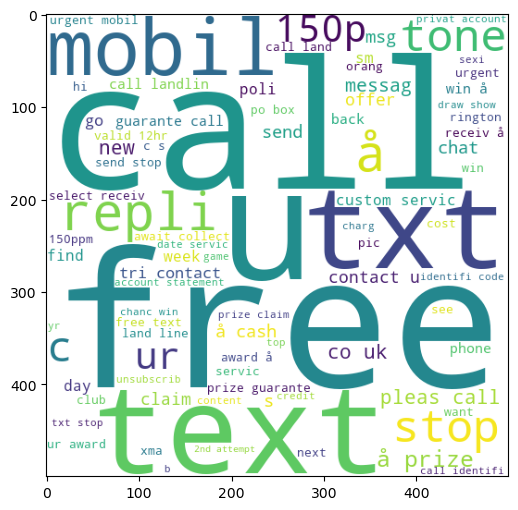

In [53]:
plt.figure(figsize=(12,6))
plt.imshow(spam_wc)

In [54]:
ham_wc = wc.generate(df[df['target']==0]['transformed_text'].str.cat(sep=" "))

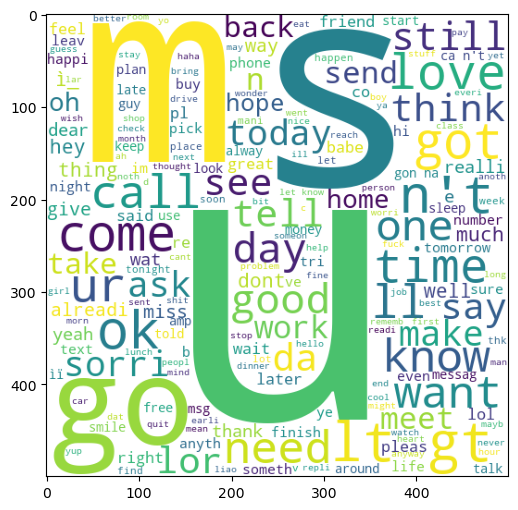

In [55]:
plt.figure(figsize=(12,6))
plt.imshow(ham_wc)

In [56]:
df.head()

,target,text,num_characters,num_words,num_sents,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi .. avail bugi n great wo...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar ... joke wif u oni ...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor ... u c alreadi say ...
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah n't think goe usf live around though


In [57]:
spam_corpus = []
for msg in df[df['target']==1]['transformed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)

In [58]:
len(spam_corpus)

11083

In [59]:
from collections import Counter
top_spam_words = pd.DataFrame(Counter(spam_corpus).most_common(30), columns=['word', 'frequency']) #Top 30 most used spam words

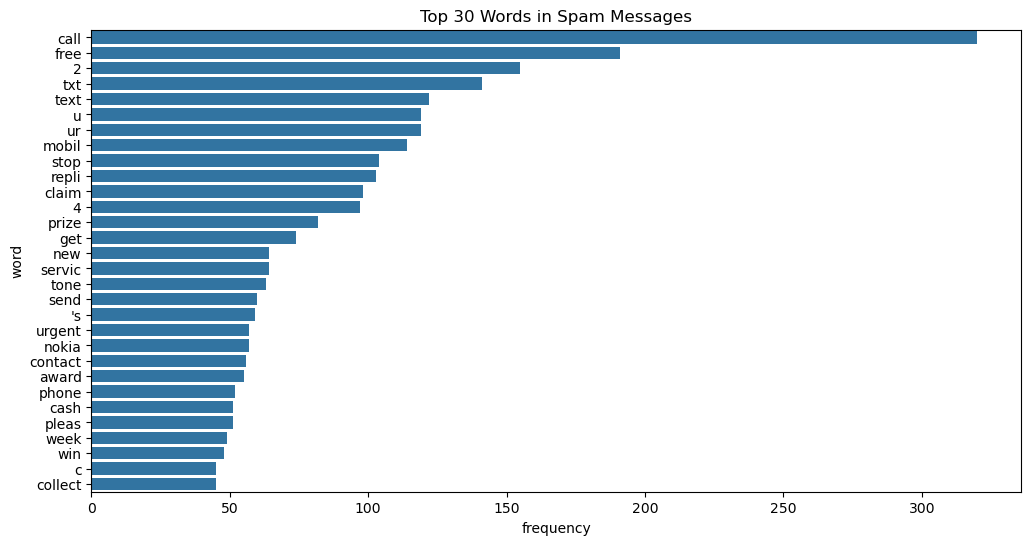

In [60]:
plt.figure(figsize=(12, 6))
sns.barplot(x='frequency', y='word', data=top_spam_words)
plt.title('Top 30 Words in Spam Messages')
plt.show()

In [61]:
ham_corpus = []
for msg in df[df['target']==0]['transformed_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

In [62]:
len(ham_corpus)

39894

In [63]:
from collections import Counter
top_ham_words = pd.DataFrame(Counter(ham_corpus).most_common(30), columns=['word', 'frequency']) #Top 30 most used ham words

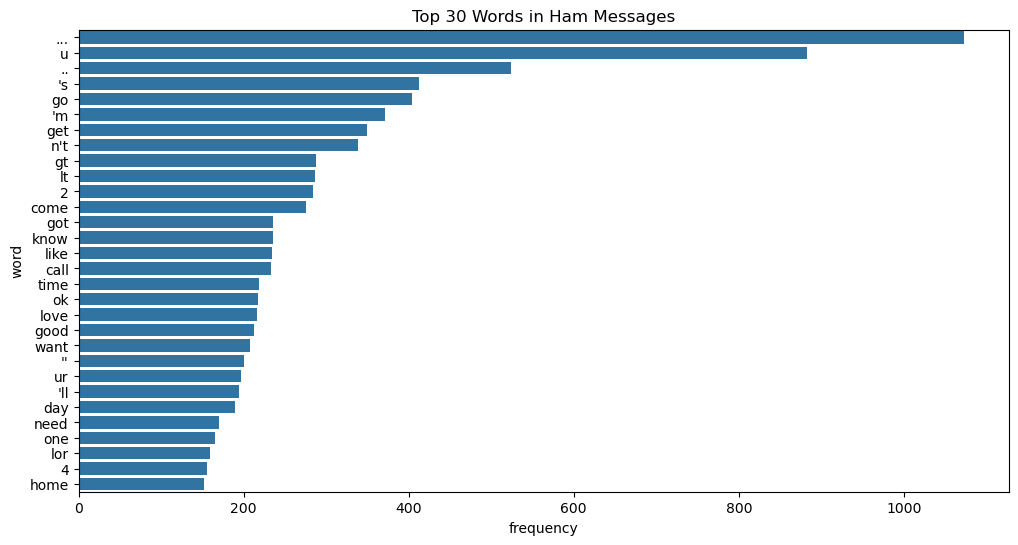

In [64]:
plt.figure(figsize=(12, 6))
sns.barplot(x='frequency', y='word', data=top_ham_words)
plt.title('Top 30 Words in Ham Messages')
plt.show()

## Model Building

In [65]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer()

In [66]:
X = tfidf.fit_transform(df['transformed_text']).toarray()

In [67]:
X.shape

(5169, 7377)

In [68]:
y = df['target'].values #values creates an array instead of a series

In [69]:
from sklearn.model_selection import train_test_split

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [71]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score

In [72]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [73]:
import sys

!{sys.executable} -m pip install imbalanced-learn

In [74]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=2)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

c:\Users\Abhra9\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Abhra9\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Abhra9\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Abhra9\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^

In [85]:
from collections import Counter
print("Before SMOTE:", Counter(y_train))
print("After SMOTE: ", Counter(y_train_resampled))

Before SMOTE: Counter({np.int64(0): 3620, np.int64(1): 515})
After SMOTE:  Counter({np.int64(0): 3620, np.int64(1): 3620})


In [75]:
gnb.fit(X_train_resampled, y_train_resampled)
y_pred1 = gnb.predict(X_test)
print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1))

0.8897485493230174
[[801  95]
 [ 19 119]]
0.5560747663551402


In [76]:
mnb.fit(X_train_resampled, y_train_resampled)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2))

0.9690522243713733
[[876  20]
 [ 12 126]]
0.863013698630137


In [77]:
bnb.fit(X_train_resampled, y_train_resampled)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3))

0.9816247582205029
[[896   0]
 [ 19 119]]
1.0


In [ ]:
# Here precision_score matters more as compared to accuracy_score
# Hence we go with BernoulliNB Naive Bayes

In [79]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_digits

In [88]:
models = {
    "Random Forest": RandomForestClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Decision Tree": DecisionTreeClassifier(),
    "Bernoulli NB": BernoulliNB(),
    "Multinomial NB": MultinomialNB()
}

In [91]:
results = []
for name, model in models.items():
    model.fit(X_train_resampled, y_train_resampled)
    
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4)
    })

df_results = pd.DataFrame(results)
print(df_results)

                 Model  Accuracy  Precision
0        Random Forest    0.9787     1.0000
1  Logistic Regression    0.9787     0.9531
2        Decision Tree    0.9594     0.8288
3         Bernoulli NB    0.9816     1.0000
4       Multinomial NB    0.9691     0.8630


In [94]:
df_results = pd.DataFrame(results)
print(df_results)

                 Model  Accuracy  Precision
0        Random Forest    0.9787     1.0000
1  Logistic Regression    0.9787     0.9531
2        Decision Tree    0.9594     0.8288
3         Bernoulli NB    0.9816     1.0000
4       Multinomial NB    0.9691     0.8630


In [95]:
# As precision is our priority, hence we choose Bernoulli NB

In [99]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(bnb,open('model.pkl','wb'))